In [1]:
import pandas as pd 
import os 

In [2]:
SHH_Alt = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\SHH_Alt.csv", index_col=0)
G4_Alt = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\G4_Alt.csv", index_col=0)
G3_Alt = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\G3_Alt.csv", index_col=0)
WNT_Alt = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\WNT_Alt.csv", index_col=0)


SHH_Ref = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\SHH_Ref.csv", index_col=0)
G4_Ref = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\G4_Ref.csv", index_col=0)
G3_Ref = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\G3_Ref.csv", index_col=0)
WNT_Ref = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\WNT_Ref.csv", index_col=0)
# Alt = pd.DataFrame({'SHH':SHH_Alt.sum(axis=1),'GP3':G3_Alt.sum(axis=1),'GP4':G4_Alt.sum(axis=1),'WNT':WNT_Alt.sum(axis=1)})!=0
# Alt = Alt.T

Alt = pd.DataFrame({'SHH':SHH_Alt.sum(axis=1),'GP3':G3_Alt.sum(axis=1),'GP4':G4_Alt.sum(axis=1),'WNT':WNT_Alt.sum(axis=1)})!=0


In [3]:
genome = pd.read_csv(r"E:\MB_Bulk_RNA_seq\retest_paired_end_correction\Annovar_analysis/184399_selected_sites_genome_summary.csv")
genome.index = genome.Chr +"_"+ genome['Start'].astype(str)
ICGC_genome = genome.loc[Alt.index]

In [4]:
merge_map = {
    'intron': 'intronic',
    'ncRNA_intronic': 'intronic',

    'ncRNA_exonic': 'exonic',

    'ncRNA_splicing': 'splicing',
    'ncRNA_exonic;splicing': 'splicing',

    'upstream': 'flanking',
    'downstream': 'flanking',
    'upstream;downstream': 'flanking',
}

ICGC_genome['Func.ensGene'] = (
    ICGC_genome['Func.ensGene'].replace(merge_map)
)

In [5]:
SHH_present = Alt[Alt['SHH'] ==True]
GP3_present = Alt[Alt['GP3'] ==True]
GP4_present = Alt[Alt['GP4'] ==True]
WNT_present = Alt[Alt['WNT'] ==True]

SHH_present_genome = ICGC_genome.loc[SHH_present.index]
GP3_present_genome = ICGC_genome.loc[GP3_present.index]
GP4_present_genome = ICGC_genome.loc[GP4_present.index]
WNT_present_genome = ICGC_genome.loc[WNT_present.index]

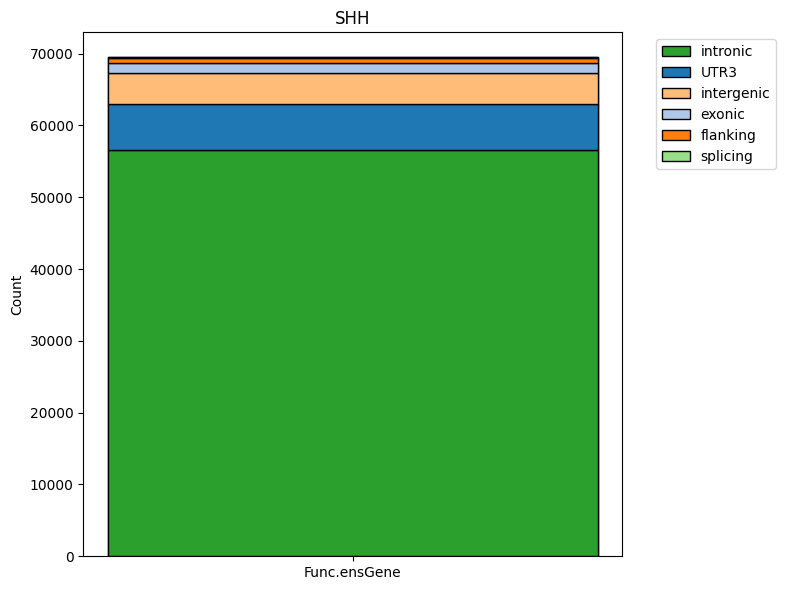

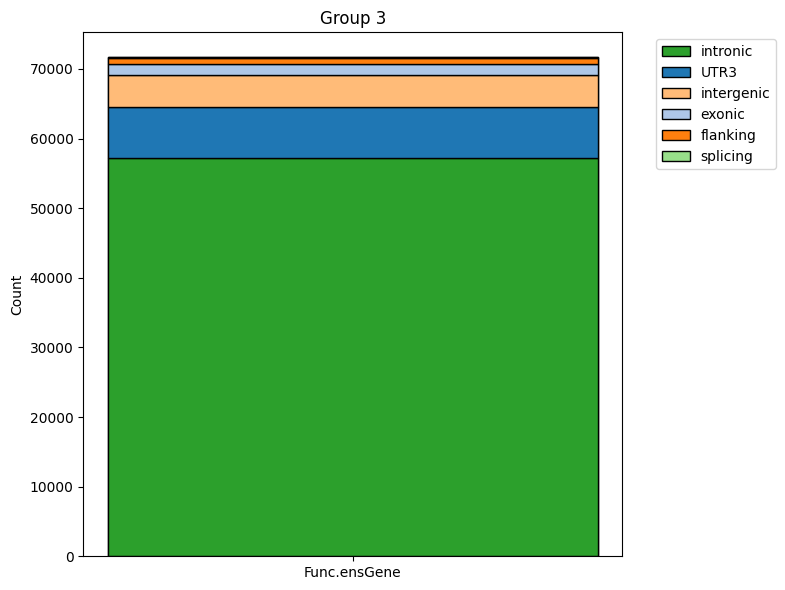

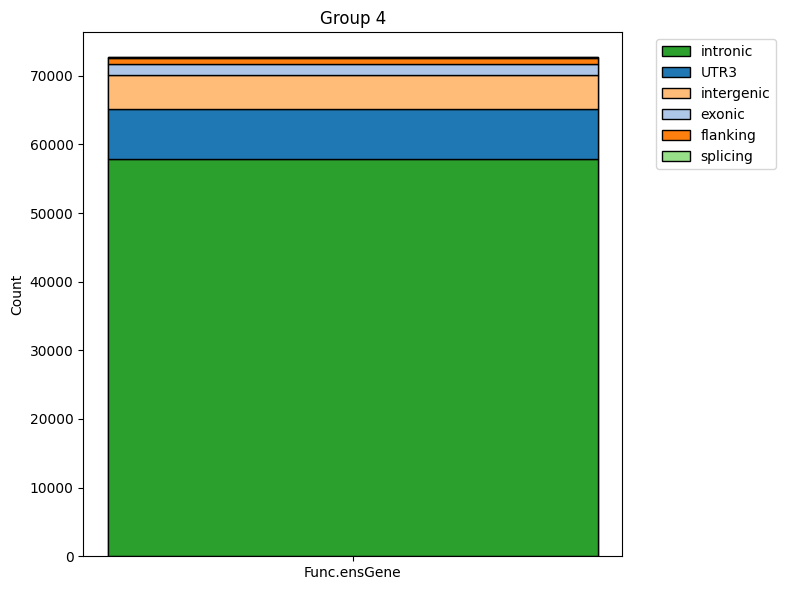

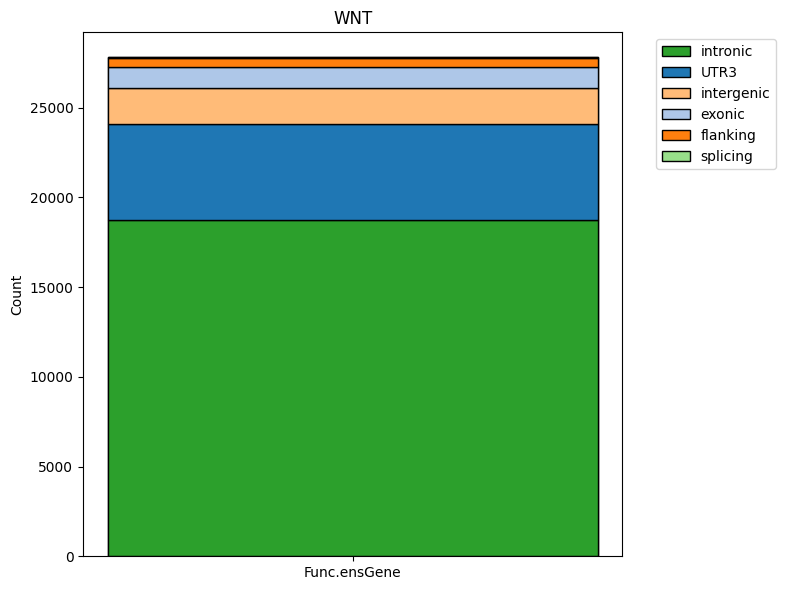

In [10]:
import matplotlib.pyplot as plt
def get_shared_color_map(dfs, column, cmap=plt.cm.tab20):
    """Build one consistent category->color mapping across multiple dataframes."""
    all_categories = set()
    for df in dfs:
        all_categories |= set(df[column].unique())
    all_categories = sorted(all_categories)
    colors = cmap.colors
    return {cat: colors[i % len(colors)] for i, cat in enumerate(all_categories)}

def plot_stacked_bar(df, column, title, color_map):
    counts = df[column].value_counts()

    plt.figure(figsize=(8, 6))
    plt.bar(column, counts.sum(), color='lightgrey', edgecolor='black')

    bottom = 0
    for category, count in counts.items():
        plt.bar(column, count, bottom=bottom,
                color=color_map[category], edgecolor='black', label=category)
        bottom += count

    plt.ylabel('Count')
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# --- Usage ---
color_map = get_shared_color_map(
    [SHH_present_genome, GP3_present_genome, GP4_present_genome, WNT_present_genome], 'Func.ensGene'
)

# plot_stacked_bar(ICGC_genome_denovo, 'Func.ensGene', 'ICGC_genome_denovo', color_map)
# plot_stacked_bar(ICGC_genome_public, 'Func.ensGene', 'ICGC_genome_public', color_map)

plot_stacked_bar(SHH_present_genome, 'Func.ensGene', 'SHH', color_map)
plot_stacked_bar(GP3_present_genome, 'Func.ensGene', 'Group 3', color_map)
plot_stacked_bar(GP4_present_genome, 'Func.ensGene', 'Group 4', color_map)
plot_stacked_bar(WNT_present_genome, 'Func.ensGene', 'WNT', color_map)


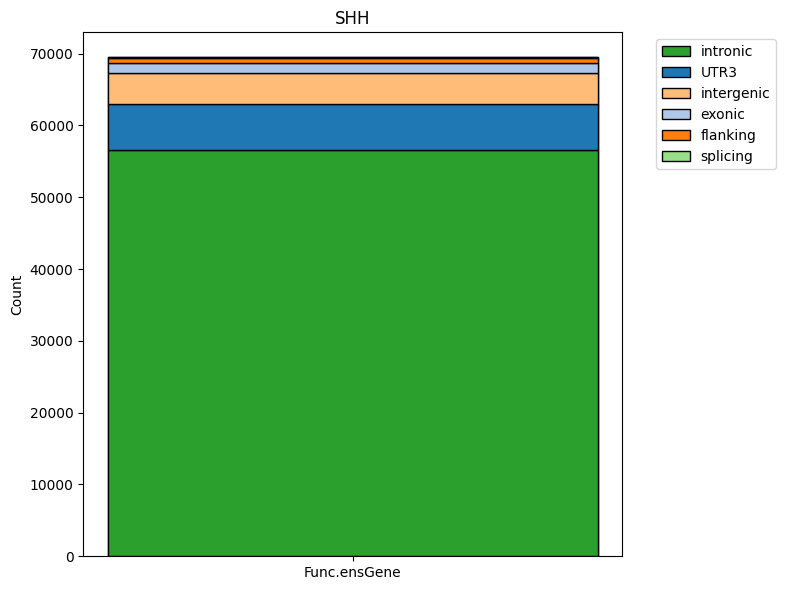

In [11]:
plot_stacked_bar(SHH_present_genome, 'Func.ensGene', 'SHH', color_map)

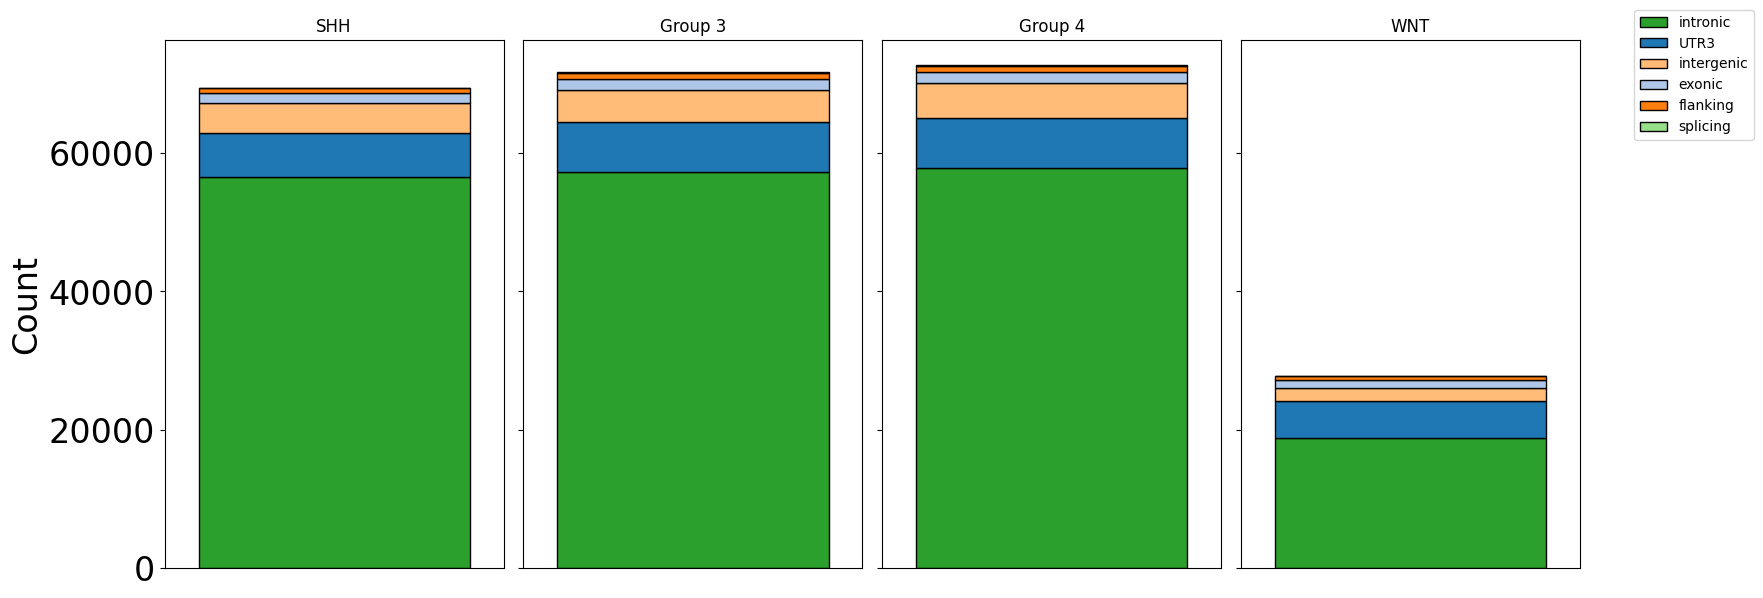

In [12]:
import matplotlib.pyplot as plt

def get_shared_color_map(dfs, column, cmap=plt.cm.tab20):
    """Build one consistent category->color mapping across multiple dataframes."""
    all_categories = set()
    for df in dfs:
        all_categories |= set(df[column].unique())
    all_categories = sorted(all_categories)
    colors = cmap.colors
    return {cat: colors[i % len(colors)] for i, cat in enumerate(all_categories)}

def plot_stacked_bar(ax, df, column, title, color_map):
    counts = df[column].value_counts()

    bottom = 0
    for category, count in counts.items():
        ax.bar(0, count, bottom=bottom,
               color=color_map[category], edgecolor='black', label=category)
        bottom += count

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_xlim(-0.5, 0.5)

# --- Usage ---
color_map = get_shared_color_map(
    [SHH_present_genome, GP3_present_genome, GP4_present_genome, WNT_present_genome], 'Func.ensGene'
)

datasets = [
    (SHH_present_genome, 'SHH'),
    (GP3_present_genome, 'Group 3'),
    (GP4_present_genome, 'Group 4'),
    (WNT_present_genome, 'WNT'),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 6), sharey=True)

for ax, (df, title) in zip(axes, datasets):
    plot_stacked_bar(ax, df, 'Func.ensGene', title, color_map)

axes[0].set_ylabel('Count', fontsize = 24)
# axes[0].set_yticks
axes[0].tick_params(axis='y', labelsize=24)

# Single shared legend for the whole figure (avoids repeating it 4x)
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))  # de-duplicate in case categories differ per panel
fig.legend(by_label.values(), by_label.keys(), bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [13]:
SHH_present = Alt[(Alt['SHH'] ==True)& (Alt['GP3'] ==False)& (Alt['GP4'] ==False) &(Alt['WNT'] ==False)]
GP3_present = Alt[(Alt['SHH'] ==False)& (Alt['GP3'] ==True)& (Alt['GP4'] ==False) &(Alt['WNT'] ==False)]
GP4_present =  Alt[(Alt['SHH'] ==False)& (Alt['GP3'] ==False)& (Alt['GP4'] ==True) &(Alt['WNT'] ==False)]
WNT_present =  Alt[(Alt['SHH'] ==False)& (Alt['GP3'] ==False)& (Alt['GP4'] ==False) &(Alt['WNT'] ==True)]

SHH_present_genome = ICGC_genome.loc[SHH_present.index]
GP3_present_genome = ICGC_genome.loc[GP3_present.index]
GP4_present_genome = ICGC_genome.loc[GP4_present.index]
WNT_present_genome = ICGC_genome.loc[WNT_present.index]

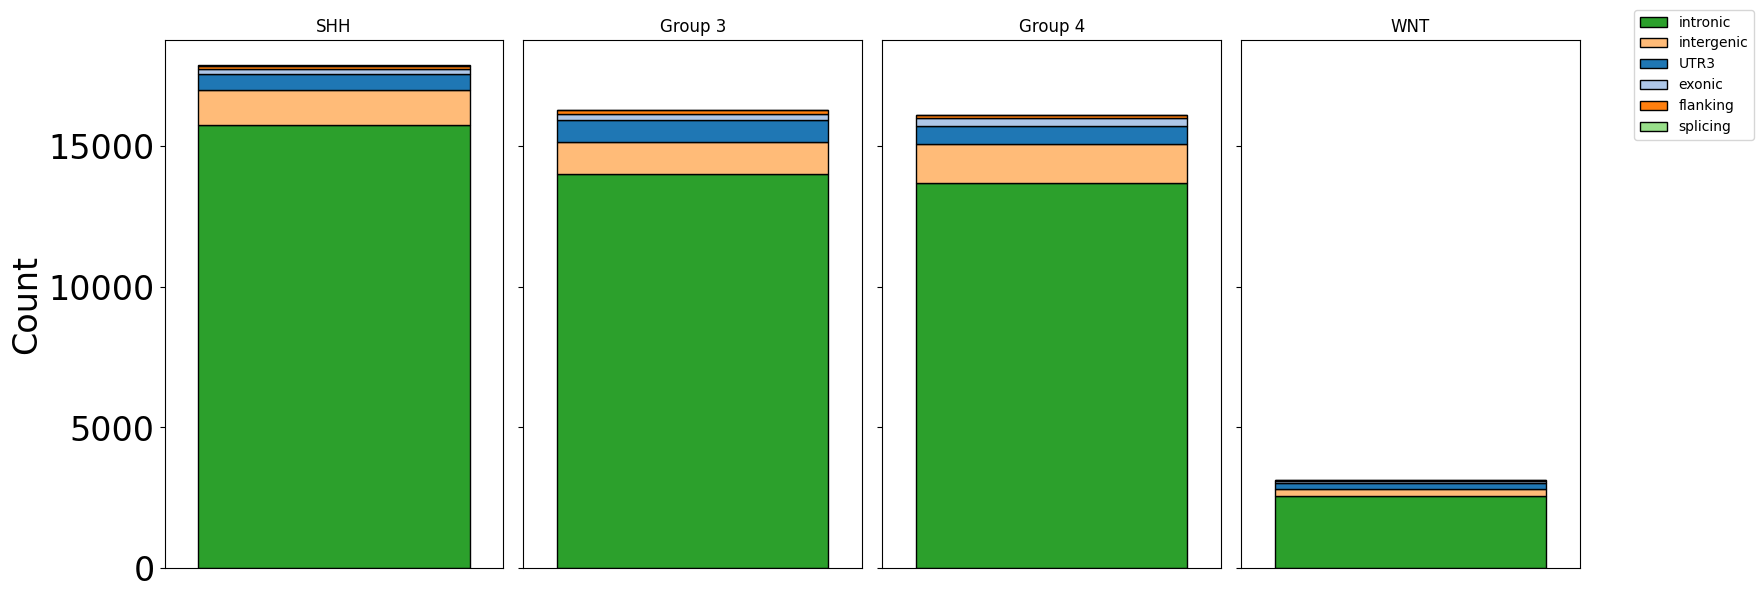

In [14]:
import matplotlib.pyplot as plt

def get_shared_color_map(dfs, column, cmap=plt.cm.tab20):
    """Build one consistent category->color mapping across multiple dataframes."""
    all_categories = set()
    for df in dfs:
        all_categories |= set(df[column].unique())
    all_categories = sorted(all_categories)
    colors = cmap.colors
    return {cat: colors[i % len(colors)] for i, cat in enumerate(all_categories)}

def plot_stacked_bar(ax, df, column, title, color_map):
    counts = df[column].value_counts()

    bottom = 0
    for category, count in counts.items():
        ax.bar(0, count, bottom=bottom,
               color=color_map[category], edgecolor='black', label=category)
        bottom += count

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_xlim(-0.5, 0.5)

# # --- Usage ---
# color_map = get_shared_color_map(
#     [SHH_present_genome, GP3_present_genome, GP4_present_genome, WNT_present_genome], 'Func.ensGene'
# )

datasets = [
    (SHH_present_genome, 'SHH'),
    (GP3_present_genome, 'Group 3'),
    (GP4_present_genome, 'Group 4'),
    (WNT_present_genome, 'WNT'),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 6), sharey=True)

for ax, (df, title) in zip(axes, datasets):
    plot_stacked_bar(ax, df, 'Func.ensGene', title, color_map)

axes[0].set_ylabel('Count', fontsize = 24)
# axes[0].set_yticks
axes[0].tick_params(axis='y', labelsize=24)

# Single shared legend for the whole figure (avoids repeating it 4x)
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))  # de-duplicate in case categories differ per panel
fig.legend(by_label.values(), by_label.keys(), bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()